# 1. Reconstructing a gravitational-wave background

Two-step reconstruction with the trained networks of the paper
([arXiv:2309.08430](https://arxiv.org/abs/2309.08430)):

1. the **TT** network infers the noise amplitude P from the TT channel (signal-free at low frequency),
2. the **AA** network infers the 26 slopes and the amplitude of the piecewise power law, given P.

No training needed: the networks are in `AA_channel/posterior_AA.pkl` and `TT_channel/posterior_TT.pkl`.

In [1]:
%matplotlib inline
import os, warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import torch
from GWBackFinder import Simulator
from GWBackFinder.noise import Omega_noiseh2_AA, Omega_noiseh2_TT
from GWBackFinder.posterior import (load_posterior, pointwise_bands, sample_two_step,
                                    spectra_from_samples)
from GWBackFinder.templates import template_omega

sim = Simulator()
torch.manual_seed(0)

## A test signal

Six template signals are available. The parameters follow the order of the Julia `z*` structs.

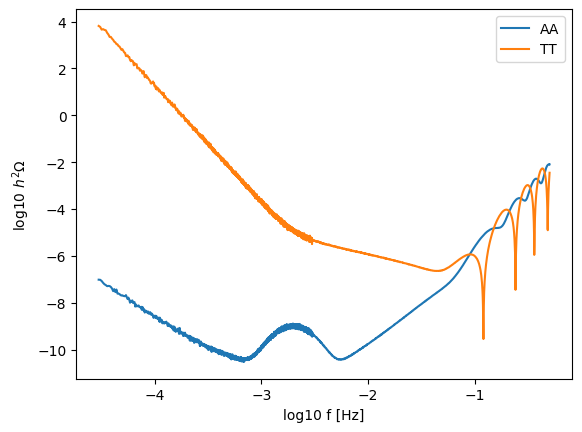

In [2]:
test_signals = {
    "powerlaw":    [-10.0, 0.6],
    "peak":        [-9.0, 0.002, 0.2],
    "wiggly":      [-10.0, 2.0, 0.1],
    "bpowerlaw":   [-11.0, -1.0, 2 / 3, 0.002],
    "dpeak":       [-11.0, -10.0, 0.001, 0.01, 0.1, 0.1],
    "three_peaks": [-10.0, -10.0, -10.0, 5e-4, 2e-3, 8e-3, 0.1, 0.1, 0.1],
}
signal = "peak"
params_noise = [15.0, 3.0]          # P, A

Data_AA, Data_TT, f_AA, f_TT = sim.different_signals(signal, test_signals[signal], params_noise, rng=0)
plt.plot(f_AA, Data_AA[:3970], label="AA")
plt.plot(f_TT, Data_TT[:3970], label="TT")
plt.xlabel("log10 f [Hz]"); plt.ylabel(r"log10 $h^2\Omega$"); plt.legend();

## Posterior samples (TT, then AA given P)

(497, 28) (497,)


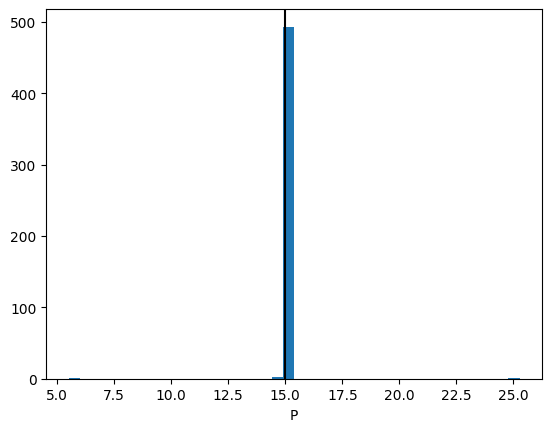

In [3]:
posterior_AA = load_posterior("AA_channel/posterior_AA.pkl")
posterior_TT = load_posterior("TT_channel/posterior_TT.pkl")

samples, samples_P = sample_two_step(posterior_AA, posterior_TT, Data_AA, Data_TT, n_samples=500)
print(samples.shape, samples_P.shape)
plt.hist(samples_P, bins=40); plt.axvline(params_noise[0], color="k"); plt.xlabel("P");

## Reconstructed spectrum

Every sample gives a spectrum; the plot shows the median and the 68% / 95% bands.

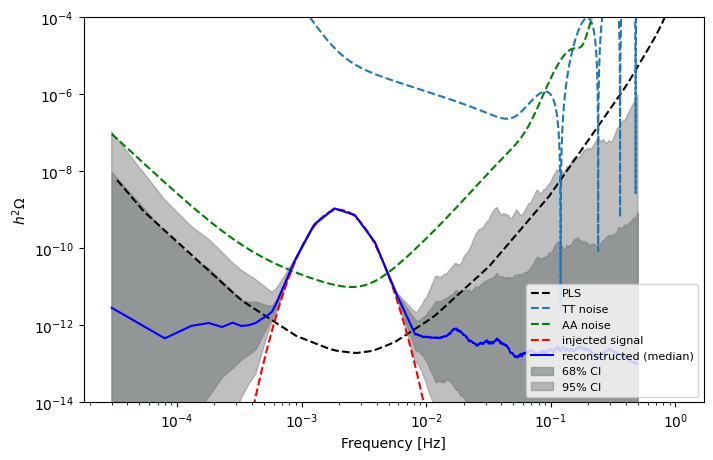

In [4]:
f = sim.f[::50]
spectra = spectra_from_samples(samples, f, sim.breakpoints)
median, bands = pointwise_bands(spectra)

pls = np.genfromtxt("plis_LISA_new_noise.dat")
fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(10 ** pls[15:, 0], 10 ** pls[15:, 1], "k--", label="PLS")
ax.loglog(f, Omega_noiseh2_TT(f, 2.5e9, 3e8, *params_noise), ls="--", label="TT noise")
ax.loglog(f, Omega_noiseh2_AA(f, 2.5e9, 3e8, *params_noise), "g--", label="AA noise")
ax.loglog(f, template_omega(signal, f, test_signals[signal]), "r--", label="injected signal")
ax.loglog(f, median, "b", label="reconstructed (median)")
ax.fill_between(f, *bands[0.68], alpha=0.7, color="#838B8B", label="68% CI")
ax.fill_between(f, *bands[0.95], alpha=0.5, color="#808080", label="95% CI")
ax.set_xlabel("Frequency [Hz]"); ax.set_ylabel(r"$h^2\Omega$"); ax.set_ylim(1e-14, 1e-4)
ax.legend(loc="lower right", fontsize=8);

## All test signals

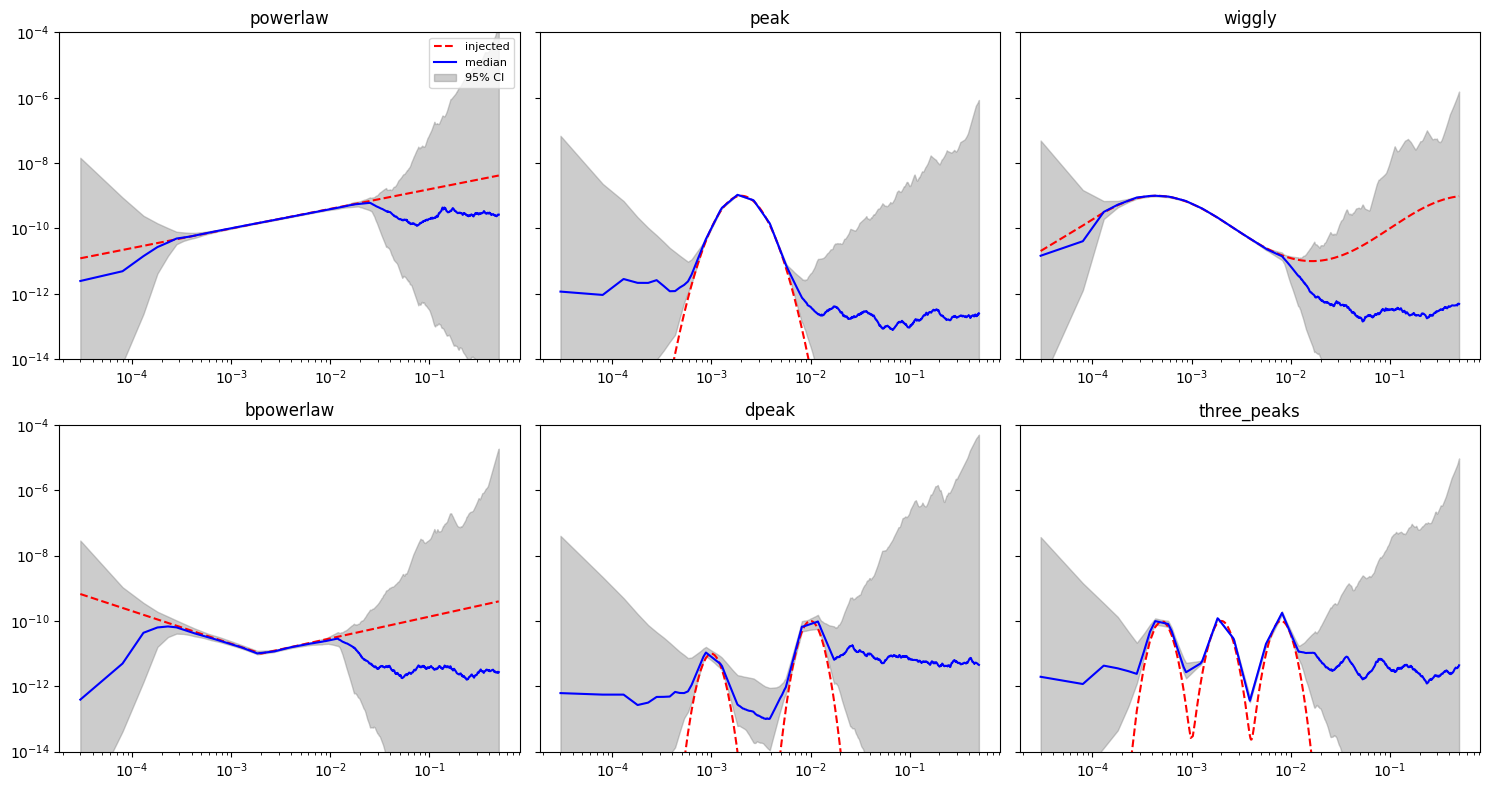

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, (name, par) in zip(axes.ravel(), test_signals.items()):
    dAA, dTT, _, _ = sim.different_signals(name, par, params_noise, rng=1)
    s, _ = sample_two_step(posterior_AA, posterior_TT, dAA, dTT, n_samples=300)
    med, bd = pointwise_bands(spectra_from_samples(s, f, sim.breakpoints))
    ax.loglog(f, template_omega(name, f, par), "r--", label="injected")
    ax.loglog(f, med, "b", label="median")
    ax.fill_between(f, *bd[0.95], alpha=0.4, color="#808080", label="95% CI")
    ax.set_title(name); ax.set_ylim(1e-14, 1e-4)
axes[0, 0].legend(fontsize=8); fig.tight_layout()